# Problem Set 1
### Cheaper food, better nutrition? Evaluating a staple-food subsidy
#### Authors: Jose Eduardo Campos Hernandez, Drishti Khemlani, Madeleine Roberts

##### Data import and cleaning code

In [3]:
# Install missing packages
packages <- c("tidyverse", "gt", "fixest", "modelsummary")
for (p in packages) {
  if (!requireNamespace(p, quietly = TRUE)) {
    install.packages(p)
  }
}

# Import packages
library(tidyverse)
library(gt)
library(fixest)
library(modelsummary)

# Add data to working directory (manual)

# Import data
staple_households <- read_csv("staple_households.csv", show_col_types = FALSE)
food_energy <- read_csv("food_energy.csv", show_col_types = FALSE)

# Clean data for analysis
raw_data <- staple_households |>
  pivot_longer(
    cols = c(rice_g, fish_g, vegetables_g, oil_g,
             rice_price_kg, fish_price_kg, vegetables_price_kg, oil_price_kg),
    names_to  = "variable",
    values_to = "value") |>
  mutate(food = str_remove(variable, "_g$|_price_kg$"),
         measure = if_else(str_ends(variable, "_g"), "grams_consumed", "price_kg")) |>
  select(-variable) |>
  pivot_wider(names_from = measure, values_from = value) |> 
  left_join(food_energy, by = "food") |> 
    transmute(household_id, 
              region, 
              treated, 
              wave, 
              baseline_resources, 
              cash_resources,
              food_spending, 
              other_spending, 
              subsidy_cost, 
              food, 
              price_g = price_kg/1000, 
              kcal_per_g,
              grams_consumed,
              food_caloric_intake = grams_consumed*kcal_per_g,
              food_share_spending = (grams_consumed*price_g)/food_spending*100)

##### **Question 1**

**We predict that households will respond to cheaper rice by consuming more rice, increasing their total calorie intake**

We expect the 25 per cent rice subsidy to increase rice consumption and calorie intake among low-income households. The subsidy makes rice cheaper relative to other foods, so the substitution effect should raise rice consumption. As rice is a high calorie food, caloric intake should increase with rice consumption. The subsidy will also have an income effect, because it leaves households with money to spare. If rice is a normal good, the income effect adds to the substitution effect. If rice is an inferior good, the income effect will offset the subsitution effect. Rice consumption would fall only if the income effect were the larger of the two, which we think unlikely given the size of the subsidy. Calorie intake will depend on how households spend the money they save. More oil, which is cheap and calorie-dense, would add calories. More fish or vegetables, which supply far fewer calories per unit of money than rice, would reduce them. Overall, our best guess is that rice consumption and calorie intake will both increase slightly.

**The data are consistent with the experimental design and contain no errors...**

The pilot follows 480 households in two regions, A and B, before, during and after the subsidy pilot. Within each region, 120 households were randomly assigned the subsidy and 120 were not. This gives 240 households in each group and 1,440 household-wave observations. There are no missing values, duplicate household-wave observations or survey attrition. No quantities or spending values are negative, and food spending plus other spending equals cash resources in every observation (Table 1)

The policy ran as designed. Treated households paid 1.80 per kg for rice during the subsidy, 25 per cent less than the usual price (Table 2). Control households paid the usual price throughout, and the prices of other foods did not change.

**... and households with and without the subsidy were similar before the pilot**

Before estimating the effects of the subsidy, we check whether households that received it (the treatment group) and households that did not (the control group) were similar before the pilot. Random assignment makes the groups alike on average, but chance differences can arise in a sample of this size. Balance tests show whether the groups look alike on what we observe; they cannot confirm that randomisation was carried out properly.

Table 3 compares the two groups on six baseline variables using Welch two-sample t-tests. The differences in resources, food spending, other spending, total calories, calories from rice and rice's share of food spending are all small; none is statistically significant, in the pooled sample or in either region. This is consistent with random assignment.

**Our outcome variable is total daily caloric intake per person**

For each household-wave observation, we multiply the grams of each food consumed per person per day by its energy content and add up the results. The energy values are 3.6 kcal per gram for rice, 1.2 for fish, 0.3 for vegetables and 9.0 for oil. The outcome is measured in kilocalories (kcal) per person per day.

In [4]:
# TABLE 1
audit <- tibble(
  Check = c("Household-wave observations","Households","Households per region and group",
            "Households observed in all three waves","Missing values","Duplicate household-wave observations",
            "Households that change region or group","Negative quantities or spending","Observations where food + other spending ≠ cash resources"),

  Result = c(nrow(staple_households),
             n_distinct(staple_households$household_id),
             paste(unique(count(distinct(staple_households, household_id, region, treated), region, treated)$n),
                   collapse = ", "),
             sum(count(staple_households, household_id)$n == 3),
             sum(is.na(staple_households)),
             sum(duplicated(staple_households[c("household_id", "wave")])),
             staple_households |>
               group_by(household_id) |>
               summarise(changes = n_distinct(region) > 1 | n_distinct(treated) > 1) |>
               pull(changes) |>
               sum(),
             sum(staple_households[c("rice_g", "fish_g", "vegetables_g", "oil_g",
                                     "food_spending", "other_spending")] < 0),
             sum(abs(staple_households$food_spending + staple_households$other_spending -
                     staple_households$cash_resources) > 1e-6)))

tbl_audit <- audit |>
  mutate(Result = as.character(Result)) |>
  gt(rowname_col = "Check") |>
  tab_header(title = "Table 1: Data audit") |>
  cols_align(align = "center", columns = Result) |>
  opt_row_striping()

IRdisplay::display_html(as_raw_html(tbl_audit))

## TABLE 2

prices <- raw_data |> 
    mutate(treated = ifelse(treated == 1, "Treated", "Control"),
    region = paste("Region", region),
    food = str_to_title(food)) |>
    group_by(food, region, wave, treated) |>
    summarise(price_kg = mean(price_g)*1000, .groups = "drop") |>
    arrange(food)

prices_wide <- prices |>
    pivot_wider(names_from = c(wave, region),
                values_from = price_kg,
                names_glue = "{wave}|{region}") |>
    select(food, treated,
            starts_with("Before"), starts_with("During"), starts_with("After"))

tbl_prices <- prices_wide |>
  gt(rowname_col = "food", groupname_col = "treated") |>
  tab_header(title = "Table 2: Price per kg by food, wave and group") |>
  tab_spanner_delim(delim = "|") |>
  fmt_number(columns = -c(treated, food), decimals = 2) |>
  cols_align(align = "center") |>
  tab_style(style = list(cell_fill(color = "grey85"), cell_text(weight = "bold")),
            locations = cells_column_spanners()) |>
  opt_row_striping() |>
    # Red box around the subsidised rice price
  tab_style(style = cell_borders(sides = c("top", "bottom"), color = "red", weight = px(2)),
            locations = cells_body(columns = c(`During|Region A`, `During|Region B`),
                                   rows = food == "Rice" & treated == "Treated")) |>
  tab_style(style = cell_borders(sides = "left", color = "red", weight = px(2)),
            locations = cells_body(columns = `During|Region A`,
                                   rows = food == "Rice" & treated == "Treated")) |>
  tab_style(style = cell_borders(sides = "right", color = "red", weight = px(2)),
            locations = cells_body(columns = `During|Region B`,
                                   rows = food == "Rice" & treated == "Treated")) |>
  tab_style(style = cell_text(color = "red", weight = "bold"),
            locations = cells_body(columns = c(`During|Region A`, `During|Region B`),
                                   rows = food == "Rice" & treated == "Treated")) |>
  tab_style(style = cell_borders(sides = c("top", "bottom"), color = "red", weight = px(2)),
            locations = cells_body(columns = c(`During|Region A`, `During|Region B`),
                                   rows = food == "Rice" & treated == "Control")) |>
  tab_style(style = cell_borders(sides = "left", color = "red", weight = px(2)),
            locations = cells_body(columns = `During|Region A`,
                                   rows = food == "Rice" & treated == "Control")) |>
  tab_style(style = cell_borders(sides = "right", color = "red", weight = px(2)),
            locations = cells_body(columns = `During|Region B`,
                                   rows = food == "Rice" & treated == "Control")) |>
  tab_style(style = cell_text(color = "red", weight = "bold"),
            locations = cells_body(columns = c(`During|Region A`, `During|Region B`),
                                   rows = food == "Rice" & treated == "Control")) |>
  tab_source_note("Mean price per kg in currency units. Treated households pay the subsidised rice price only in the During wave.")

IRdisplay::display_html(as_raw_html(tbl_prices))

<table class="gt_table" data-quarto-disable-processing="false" data-quarto-bootstrap="false" style="-webkit-font-smoothing: antialiased; -moz-osx-font-smoothing: grayscale; font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji'; display: table; border-collapse: collapse; line-height: normal; margin-left: auto; margin-right: auto; color: #333333; font-size: 16px; font-weight: normal; font-style: normal; background-color: #FFFFFF; width: auto; border-top-style: solid; border-top-width: 2px; border-top-color: #A8A8A8; border-right-style: none; border-right-width: 2px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #A8A8A8; border-left-style: none; border-left-width: 2px; border-left-color: #D3D3D3;" bgcolor="#FFFFFF">
 
 
 <td colspan="2" class="gt_heading gt_title gt_font_normal gt_bottom_border" style="border-style: none; color: #333333; font-size: 125%; padding-top: 4px; padding-bottom: 4px; padding-left: 5px; padding-right: 5px; background-color: #FFFFFF; text-align: center; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; border-bottom-style: solid; border-bottom-width: 2px; border-bottom-color: #D3D3D3; font-weight: normal;" bgcolor="#FFFFFF" align="center">Table 1: Data audit 
 
 
 
 <th class="gt_col_heading gt_columns_bottom_border gt_left" rowspan="1" colspan="1" scope="col" id="a::stub" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: left;" bgcolor="#FFFFFF" valign="bottom" align="left"> 
 <th class="gt_col_heading gt_columns_bottom_border gt_center" rowspan="1" colspan="1" scope="col" id="Result" style="border-style: none; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: normal; text-transform: inherit; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; border-right-style: none; border-right-width: 1px; border-right-color: #D3D3D3; vertical-align: bottom; padding-top: 5px; padding-bottom: 6px; padding-left: 5px; padding-right: 5px; overflow-x: hidden; text-align: center;" bgcolor="#FFFFFF" valign="bottom" align="center">Result 
 
 
 
 <th id="stub_1_1" scope="row" class="gt_row gt_left gt_stub" style="border-style: none; padding-top: 8px; padding-bottom: 8px; margin: 10px; border-top-style: solid; border-top-width: 1px; border-top-color: #D3D3D3; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; vertical-align: middle; overflow-x: hidden; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: initial; text-transform: inherit; border-right-style: solid; border-right-width: 2px; border-right-color: #D3D3D3; padding-left: 5px; padding-right: 5px; text-align: left;" valign="middle" bgcolor="#FFFFFF" align="left">Household-wave observations 
 1440 
 <th id="stub_1_2" scope="row" class="gt_row gt_left gt_stub" style="border-style: none; padding-top: 8px; padding-bottom: 8px; margin: 10px; border-top-style: solid; border-top-width: 1px; border-top-color: #D3D3D3; border-left-style: none; border-left-width: 1px; border-left-color: #D3D3D3; vertical-align: middle; overflow-x: hidden; color: #333333; background-color: #FFFFFF; font-size: 100%; font-weight: initial; text-transform: inherit; border-right-style: solid; border-right-width: 2px; border-right-color: #D3D3D3; padding-left: 5px; padding-right: 5px; text-align: left;" valign="middle" bgcolor="#FFFFFF" align="left">Households 
<td headers="stub_1_2 Resu

Mean price per kg in currency units. Treated households pay the subsidised rice price only in the During wave.


In [5]:
# Analysis to check randomisation
check_data <- raw_data |> 
  mutate(flag = if_else(treated == 1, "Treated", "Control")) |> 
  filter(wave == "Before") |>
  group_by(household_id) |> 
  mutate(total_caloric_intake = sum(food_caloric_intake)) |> 
  ungroup() |> 
  filter(food == "rice")

balance_total <-  check_data |> 
  select(flag, baseline_resources, food_spending, other_spending, total_caloric_intake, food_caloric_intake, food_share_spending) |> 
  pivot_longer(!flag) |> 
  group_by(name) |> 
  summarise(Control = mean(value[flag == "Control"]),
            Treated = mean(value[flag == "Treated"]),
            diff    = Treated - Control,
            t_stat  = t.test(value[flag == "Treated"], value[flag == "Control"])$statistic,
            p_value = t.test(value[flag == "Treated"], value[flag == "Control"])$p.value) |> 
  mutate(signif = case_when(p_value < 0.01 ~ "***",
                            p_value < 0.05 ~ "**",
                            p_value < 0.10 ~ "*",
                            TRUE           ~ ""))

balance_A <- check_data |> 
  filter(region == "A") |> 
  select(flag, baseline_resources, food_spending, other_spending, total_caloric_intake, food_caloric_intake, food_share_spending) |> 
  pivot_longer(!flag) |> 
  group_by(name) |> 
  summarise(Control = mean(value[flag == "Control"]),
            Treated = mean(value[flag == "Treated"]),
            diff    = Treated - Control,
            t_stat  = t.test(value[flag == "Treated"], value[flag == "Control"])$statistic,
            p_value = t.test(value[flag == "Treated"], value[flag == "Control"])$p.value) |> 
  mutate(signif = case_when(p_value < 0.01 ~ "***",
                            p_value < 0.05 ~ "**",
                            p_value < 0.10 ~ "*",
                            TRUE           ~ ""))

balance_B <- check_data |> 
  filter(region == "B") |> 
  select(flag, baseline_resources, food_spending, other_spending, total_caloric_intake, food_caloric_intake, food_share_spending) |> 
  pivot_longer(!flag) |> 
  group_by(name) |> 
  summarise(Control = mean(value[flag == "Control"]),
            Treated = mean(value[flag == "Treated"]),
            diff    = Treated - Control,
            t_stat  = t.test(value[flag == "Treated"], value[flag == "Control"])$statistic,
            p_value = t.test(value[flag == "Treated"], value[flag == "Control"])$p.value) |> 
  mutate(signif = case_when(p_value < 0.01 ~ "***",
                            p_value < 0.05 ~ "**",
                            p_value < 0.10 ~ "*",
                            TRUE           ~ ""))

balance <- bind_rows("Total"    = balance_total,
                     "Region A" = balance_A,
                     "Region B" = balance_B,
                     .id = "sample")

# Code for table
labels <- c(baseline_resources = "Baseline resources",
            food_spending      = "Food spending",
            other_spending     = "Other spending",
            total_caloric_intake = "Total calorie intake (kcal/person/day)",
            food_caloric_intake = "Calories from rice (kcal/person/day)",
            food_share_spending  = "Share of spending on rice (%)")

balance_wide <- balance |> 
  mutate(Variable   = unname(labels[name]),
         Treatment  = Treated,
         Comparison = Control,
         `T-stat`   = paste0(sprintf("%.2f", t_stat), signif)) |> 
  select(sample, Variable, Treatment, Comparison, `T-stat`) |> 
  pivot_wider(names_from  = sample,
              values_from = c(Treatment, Comparison, `T-stat`),
              names_glue  = "{sample}|{.value}") |> 
  select(Variable, starts_with("Total"), starts_with("Region A"), starts_with("Region B"))

tbl1 <- balance_wide |> 
  gt(rowname_col = "Variable") |> 
  tab_header(title = "Table 3: Covariate Balance before the Subsidy") |> 
  tab_spanner_delim(delim = "|") |> 
  fmt_number(columns = matches("Treatment|Comparison"), decimals = 2) |> 
  cols_align(align = "center") |> 
  tab_style(style = list(cell_fill(color = "grey85"), cell_text(weight = "bold")),
            locations = cells_column_spanners()) |> 
  opt_row_striping() |> 
  tab_source_note("Welch two-sample t-statistics comparing treatment and control group means before the subsidy. * p < 0.10, ** p < 0.05, *** p < 0.01")

IRdisplay::display_html(as_raw_html(tbl1))

"Welch two-sample t-statistics comparing treatment and control group means before the subsidy. * p < 0.10, ** p < 0.05, *** p < 0.01"


##### Question 2

**Consumption and expenditure patterns vary between households with and without the rice subsidy across survey waves**

Table 4 presents average household resources, food and non-food expenditure, rice consumption and total calorie intake across treatment groups and survey waves. These variables were selected to examine household purchasing power, expenditure allocation and nutritional outcomes before, during and after the intervention.

Before the subsidy, treatment and control households exhibited similar consumption and expenditure patterns. During the intervention, average rice consumption among treated households declined from 497.72 to 459.97 grams per person per day, while total calorie intake fell from 2,133.44 to 2,051.55 kcal per person per day. In comparison, control households experienced smaller declines in both variables. Interestingly, treated households' food expenditure increased from 2.69 to 2.76 currency units per person per day, despite their lower rice consumption and calorie intake.

Following the withdrawal of the subsidy, rice consumption and total calorie intake returned close to their baseline levels in both groups. These patterns raise the possibility that households adjusted their consumption bundles in response to changing relative prices, potentially reallocating expenditure towards other foods. However, these descriptive statistics cannot establish the underlying mechanism or the causal effect of the subsidy.

The observed differences in Table 4 motivate a subsequent evaluation comparing changes in outcomes between treated and control households, while examining whether changes in food composition help explain the observed patterns.

In [6]:
calorie_data <- raw_data |>
  group_by(household_id, region, treated, wave) |>
  summarise(
    total_calories = sum(food_caloric_intake),
    .groups = "drop"
  )
  desc_labels <- c(mean_resources      = "Cash resources",
                 mean_food_spending  = "Food spending",
                 mean_other_spending = "Other spending",
                 mean_rice_g         = "Rice consumed (g/person/day)",
                 mean_calories       = "Total calorie intake (kcal/person/day)")

descriptive_table <- staple_households |>
  left_join(calorie_data, by = c("household_id", "region", "treated", "wave")) |>
  mutate(Group = if_else(treated == 1, "Treatment", "Comparison"),
         wave  = factor(wave, levels = c("Before", "During", "After"))) |>
  group_by(wave, Group) |>
  summarise(mean_resources      = mean(cash_resources),
            mean_food_spending  = mean(food_spending),
            mean_other_spending = mean(other_spending),
            mean_rice_g         = mean(rice_g),
            mean_calories       = mean(total_calories),
            .groups = "drop") |>
  pivot_longer(starts_with("mean_"), names_to = "name") |>
  mutate(Variable = factor(desc_labels[name], levels = desc_labels)) |>
  select(Variable, wave, Group, value) |>
  pivot_wider(names_from = c(wave, Group), values_from = value,
              names_glue = "{wave}|{Group}") |>
  arrange(Variable) |>
  select(Variable,
         `Before|Treatment`, `Before|Comparison`,
         `During|Treatment`, `During|Comparison`,
         `After|Treatment`,  `After|Comparison`)

tbl2 <- descriptive_table |>
  gt(rowname_col = "Variable") |>
  tab_header(title = "Table 4: Resources, Spending and Calories by Wave and Group") |>
  tab_spanner_delim(delim = "|") |>
  fmt_number(columns = -Variable, decimals = 2) |>
  cols_align(align = "center") |>
  tab_style(style = list(cell_fill(color = "grey85"), cell_text(weight = "bold")),
            locations = cells_column_spanners()) |>
  opt_row_striping() |>
  tab_source_note("Group means per person per day; 240 treatment and 240 comparison households in each wave. Resources and spending in currency units.")

IRdisplay::display_html(as_raw_html(tbl2))

Group means per person per day; 240 treatment and 240 comparison households in each wave. Resources and spending in currency units.


**Rice is the main source of household calories**

Figure 1 illustrates the composition of average daily calorie intake before the intervention. Rice accounts for approximately 84 per cent of total calories consumed, followed by oil, fish and vegetables, which contribute substantially smaller shares.

The dominance of rice suggests that household nutrition is highly dependent on staple-food consumption. Consequently, changes in rice demand may have a substantial influence on total calorie intake, making the rice subsidy particularly relevant to the government's nutritional objective. The importance of rice in the baseline diet does not necessarily imply that a reduction in its price will increase calorie intake. Households may reallocate consumption towards other foods as their purchasing power increases. Figure 1 highlights the question of whether changes in dietary composition can offset changes in rice consumption, which will be investigated in the subsequent analysis.

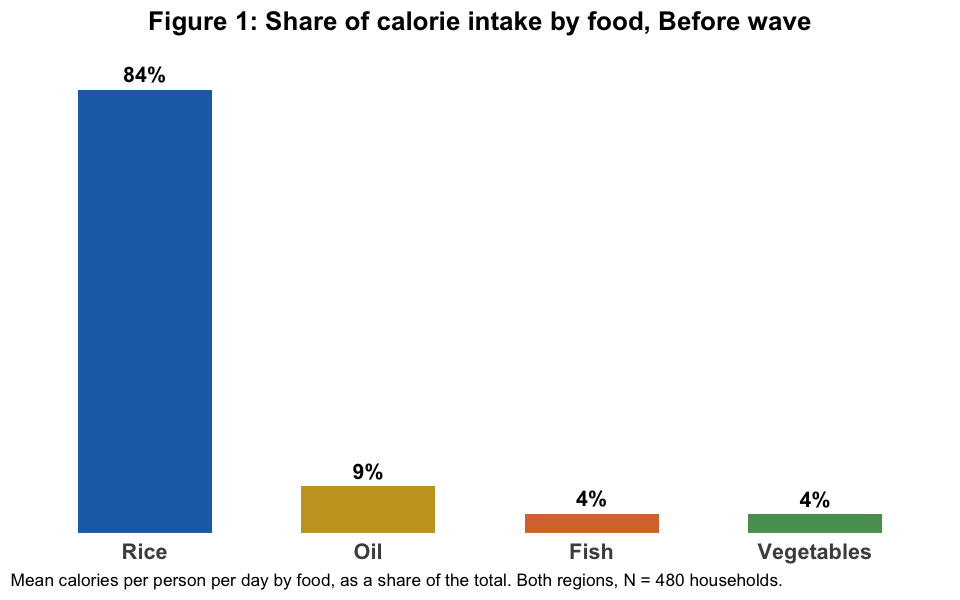

In [7]:
options(repr.plot.width = 8, repr.plot.height = 5)

# share of calories by food in the Before wave (both regions)
food_composition <- raw_data |>
  filter(wave == "Before") |>
  group_by(food) |>
  summarise(mean_calories = mean(food_caloric_intake), .groups = "drop") |>
  mutate(calorie_share = mean_calories / sum(mean_calories),
         food = fct_reorder(str_to_title(food), calorie_share, .desc = TRUE))

# ordered from largest to smallest share
ggplot(food_composition, aes(food, calorie_share, fill = food)) +
  geom_col(width = 0.6) +
  geom_text(aes(label = scales::percent(calorie_share, accuracy = 1)),
            vjust = -0.5, fontface = "bold", size = 4.5) +

  scale_fill_manual(values = c(Rice       = "#1f6fb4",
                               Oil        = "#c9a227",
                               Fish       = "#d9773b",
                               Vegetables = "#5a9e5f"),
                    guide = "none") +
  scale_y_continuous(expand = expansion(mult = c(0, 0.1))) +

  labs(title = "Figure 1: Share of calorie intake by food, Before wave",
       x = NULL, y = NULL,
       caption = "Mean calories per person per day by food, as a share of the total. Both regions, N = 480 households.") +

  theme_minimal(base_size = 13) +
  theme(panel.grid = element_blank(),
        axis.text.x = element_text(size = 13, face = "bold"),
        axis.text.y = element_blank(),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0),
        plot.caption.position = "plot")

**Baseline calorie intake differs across households, suggesting that average outcomes may hide heterogeneity in responses to the subsidy**

Figure 2 presents the distribution of total daily calorie intake across the 480 households before the intervention. The distribution is approximately unimodal, with most households consuming between 2,000 and 2,300 kcal per person per day. However, calorie intake varies considerably, with observations ranging from approximately 1,750 to 2,650 kcal per person per day.

This variation suggests that average calorie intake may conceal meaningful differences in households' initial consumption levels. Consequently, the subsidy may have heterogeneous implications for households with relatively low versus high baseline calorie intake.

Figure 2 motivates further investigation into whether the policy's effects differ according to initial household circumstances, rather than relying exclusively on an overall average treatment effect.

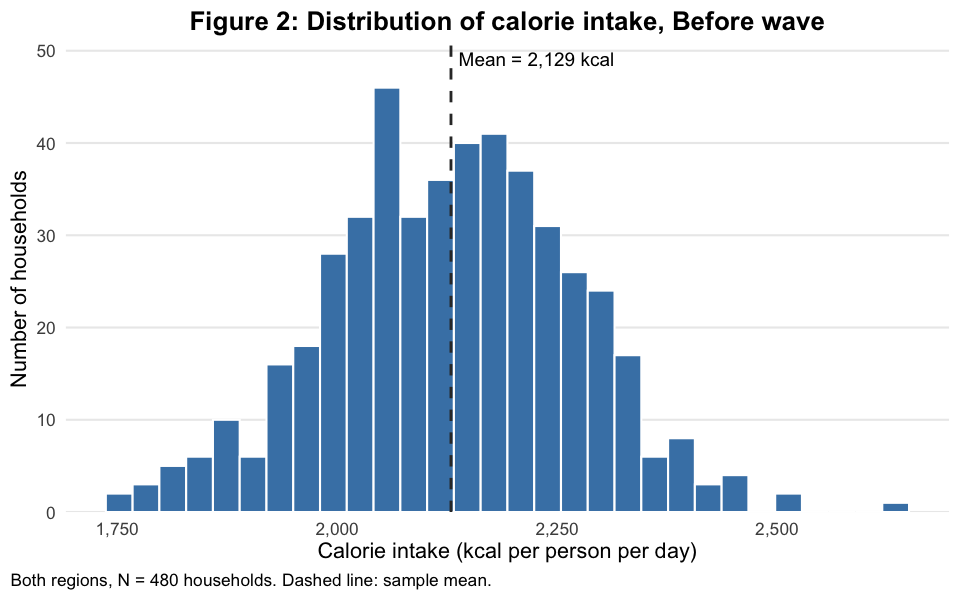

In [8]:
options(repr.plot.width = 8, repr.plot.height = 5)

# Data: total calories per household in the Before wave
baseline_calories <- raw_data |>
  filter(wave == "Before") |>
  group_by(household_id) |>
  summarise(total_calories = sum(food_caloric_intake), .groups = "drop")

mean_kcal <- mean(baseline_calories$total_calories)

# Histogram with the sample mean
ggplot(baseline_calories, aes(total_calories)) +
  geom_histogram(bins = 30, fill = "steelblue", colour = "white") +
  geom_vline(xintercept = mean_kcal, linetype = "dashed", colour = "grey20", linewidth = 0.8) +
  annotate("text", x = mean_kcal, y = Inf,
           label = paste0("Mean = ", format(round(mean_kcal), big.mark = ","), " kcal"),
           hjust = -0.05, vjust = 1.5, size = 4) +

  # Scales: bars start at the base, thousands separator on the x axis
  scale_x_continuous(labels = scales::comma) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.1))) +

  # Titles and notes
  labs(title = "Figure 2: Distribution of calorie intake, Before wave",
       x = "Calorie intake (kcal per person per day)", y = "Number of households",
       caption = "Both regions, N = 480 households. Dashed line: sample mean.") +

  # Visual style
  theme_minimal(base_size = 13) +
  theme(panel.grid.minor = element_blank(),
        panel.grid.major.x = element_blank(),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0),
        plot.caption.position = "plot")

##### Question 3

**We compare treated and control households using a difference-in-differences estimation**

We use a difference-in-differences comparison to compare the change in calorie intake of treated households with the change for control households in the same region over the same waves. We can make this comparison since the subsidy affects only some households and we observe calorie intake before, during and after the treatment for both treated and untreated groups. 

A key assumption of our difference-in-differences estimation is parallel trends: unobservables that affect the outcome should not vary differently in time between treated and control units. Parallel trends holds by design in expectation, because randomisation makes the two groups the same in every way apart from the subsidy. Table 3 supports this: the two groups were alike before the pilot.

We estimate:

$$Y_{it} = \alpha_i + \lambda_{r(i)t} + \beta_D\,(T_i \times \text{During}_t) + \beta_A\,(T_i \times \text{After}_t) + \varepsilon_{it}$$

where:
- $Y_{it}$ is the total calorie intake of household $i$ in wave $t$, in kcal per person per day, summed over rice, fish, vegetables and oil.
- $\alpha_i$ is a household fixed effect, which absorbs every household characteristic that does not change across waves.
- $\lambda_{r(i)t}$ is a region $\times$ wave fixed effect, which absorbs shocks common to all households in a region in a given wave. These fixed effects were chosen since randomisation was done within region.
- $T_i = 1$ if household $i$ was randomly assigned to the subsidy, and $0$ otherwise.
- $\text{During}_t$ and $\text{After}_t$ are wave indicators. The Before wave is the omitted reference.
Including region and time period fixed effects allow our comparison to be informative about the policy because we are controlling for differences between households and changes over time. $\beta_D$ is the effect of the subsidy while it was in place. $\beta_A$ shows whether any effect lasted after it ended. We cluster standard errors by household, because each household is observed three times. 

The estimation and an extension shown in Tables 5 and 6.

##### Question 4

**We find no evidence that the subsidy improved calorie intake for the pooled sample**

Our difference-in-differences estimates are shown in Table 5. They suggest that while the subsidy was in place, treated households consumed 46.0 kcal less per person per day than control households (95 per cent confidence interval: 26.6 to 65.4 kcal less), significant at the 1 per cent level. After the subsidy ended, the difference was –3.7 kcal and not significant, so the effect did not last. This can be seen visually in Figure 3.

In [9]:
regression_data <- raw_data |>
  group_by(household_id, region, treated, wave) |>
  summarise(total_caloric_intake = sum(food_caloric_intake), .groups = "drop") |>
  mutate(wave = factor(wave, levels = c("Before", "During", "After")),
         wave_during = as.integer(wave == "During"),
         wave_after  = as.integer(wave == "After"))

did <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after |
               household_id + region^wave,
             data = regression_data, cluster = ~household_id)

tbl_did <- modelsummary(
  list("Total calorie intake" = did),
  coef_map  = c("treated:wave_during" = "Treated × During",
                "treated:wave_after"  = "Treated × After"),
  statistic = c("({std.error})", "[{conf.low}, {conf.high}]"),
  fmt       = 1,
  stars     = c("*" = 0.10, "**" = 0.05, "***" = 0.01),
  gof_map   = list(list(raw = "nobs", clean = "Observations", fmt = function(x) format(x, big.mark = ",")),
                   list(raw = "r.squared", clean = "R²", fmt = 3)),
  output    = "gt") |>
  tab_header(title = "Table 5: Effect of the Rice Subsidy on Calorie Intake") |>
  cols_align(align = "center", columns = -1) |>
  tab_style(style = list(cell_fill(color = "grey85"), cell_text(weight = "bold")),
            locations = cells_column_labels()) |>
  tab_source_note("Dependent variable: total calorie intake in kcal per person per day. Difference-in-differences estimates relative to the Before wave, with household and region × wave fixed effects. Standard errors clustered by household in parentheses; 95% confidence intervals in brackets. 480 households observed in three waves.")

IRdisplay::display_html(as_raw_html(tbl_did))

"* p < 0.1, ** p < 0.05, *** p < 0.01"
"Dependent variable: total calorie intake in kcal per person per day. Difference-in-differences estimates relative to the Before wave, with household and region × wave fixed effects. Standard errors clustered by household in parentheses; 95% confidence intervals in brackets. 480 households observed in three waves."


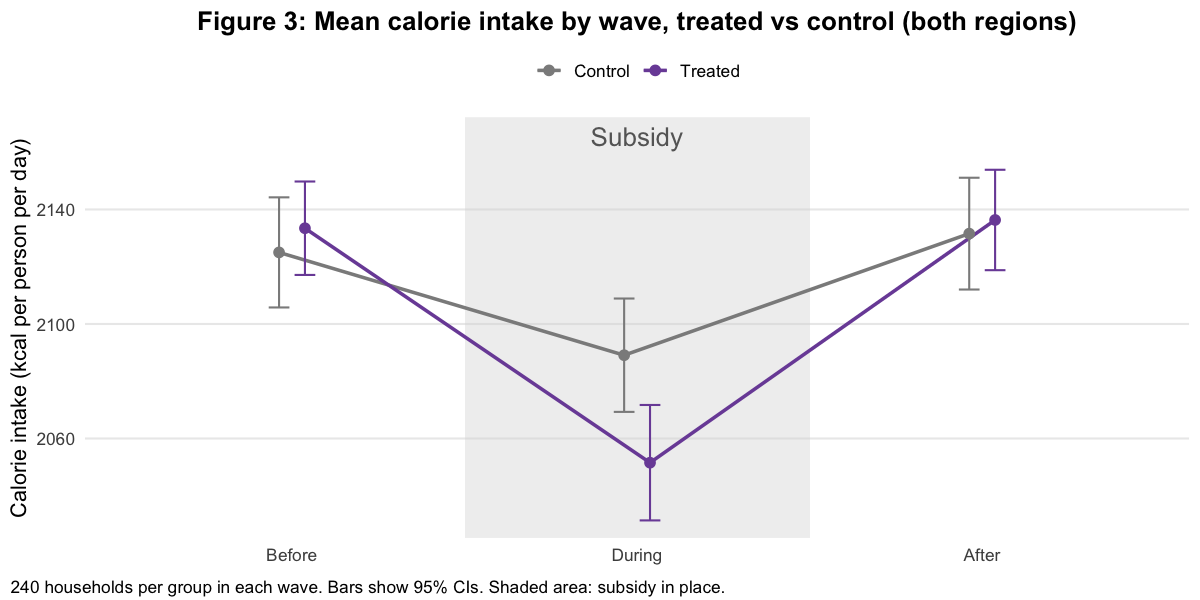

In [10]:
# Plot settings: spacing between groups and figure size
dodge <- position_dodge(0.15)
options(repr.plot.width = 10, repr.plot.height = 5)

# ---- Both regions ----

# Data: mean and SE of calorie intake by wave and group
regression_data |>
  mutate(wave  = factor(wave, levels = c("Before", "During", "After")),
         group = if_else(treated == 1, "Treated", "Control")) |>
  group_by(wave, group) |>
  summarise(mean_kcal = mean(total_caloric_intake),
            se = sd(total_caloric_intake) / sqrt(n()),
            .groups = "drop") |>

  # Axes: wave on x, mean calories on y, one line per group
  ggplot(aes(wave, mean_kcal, colour = group, group = group)) +

  # Shaded area and label for the During wave (subsidy in place)
  annotate("rect", xmin = 1.5, xmax = 2.5, ymin = -Inf,
           ymax = Inf, fill = "grey85", alpha = 0.4) +
  annotate("text", x = 2, y = Inf, label = "Subsidy",
           vjust = 1.5, colour = "grey40", size = 5.5) +

  # Means with 95% confidence intervals
  geom_line(position = dodge, linewidth = 1) +
  geom_point(position = dodge, size = 2.5) +
  geom_errorbar(aes(ymin = mean_kcal - 1.96 * se, ymax = mean_kcal + 1.96 * se),
                width = 0.12, position = dodge) +

  # Scales: discrete x axis, extra space on top for the label, group colours
  scale_x_discrete() +
  scale_y_continuous(expand = expansion(mult = c(0.05, 0.15))) +
  scale_colour_manual(values = c(Control = "grey55", Treated = "#7b4fa6")) +

  # Titles and notes
  labs(title = "Figure 3: Mean calorie intake by wave, treated vs control (both regions)",
       x = NULL, y = "Calorie intake (kcal per person per day)", colour = NULL,
       caption = "240 households per group in each wave. Bars show 95% CIs. Shaded area: subsidy in place.") +

  # Visual style
  theme_minimal(base_size = 13) +
  theme(legend.position = "top",
        panel.grid.minor = element_blank(),
        panel.grid.major.x = element_blank(),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0, vjust = -1),
        plot.caption.position = "plot")


**Households in Region A especially reduced their intake of calories in response to the price subsidy**

Considering the regions separately, we find differences in households from region A and B responded to the subsidy. The subsidy lowered calorie intake in region A and raised it slightly in region B (Table 6).
- In region A, treated households consumed 127 kcal less per person per day than control households while the subsidy was in place (95 per cent confidence interval: 100 to 153 kcal less).
- In region B, treated households consumed 35 kcal more (95 per cent confidence interval: 10 to 59 kcal more).
The difference between the regions is 161 kcal, with a standard error of 18 kcal, so it is highly statistically significant. In both regions, the effect disappears once the subsidy ends.

The pooled estimate of –46 kcal is simply the average of these two opposite effects. Figure 4 shows the same pattern in the raw means: the treated and control lines move together except in the During wave.

In [11]:
regression_data <- raw_data |>
  group_by(household_id, region, treated, wave) |>
  summarise(total_caloric_intake = sum(food_caloric_intake), .groups = "drop") |>
  mutate(wave_during = as.integer(wave == "During"),
         wave_after  = as.integer(wave == "After"),
         region_b    = as.integer(region == "B"))

did <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after |
               household_id + region^wave,
             data = regression_data, cluster = ~household_id)

did_a <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after |
                 household_id + wave,
               data = filter(regression_data, region == "A"), cluster = ~household_id)

did_b <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after |
                 household_id + wave,
               data = filter(regression_data, region == "B"), cluster = ~household_id)

did_diff <- feols(total_caloric_intake ~ treated:wave_during + treated:wave_after +
                    treated:wave_during:region_b + treated:wave_after:region_b |
                    household_id + region^wave,
                  data = regression_data, cluster = ~household_id)

tbl5 <- modelsummary(list("Pooled" = did, "Region A" = did_a, "Region B" = did_b, "Difference" = did_diff),
                     coef_map = c("treated:wave_during"          = "Treated × During",
                                  "treated:wave_after"           = "Treated × After",
                                  "treated:wave_during:region_b" = "Treated × During × Region B",
                                  "treated:wave_after:region_b"  = "Treated × After × Region B"), # nolint
                     stars   = c("*" = 0.10, "**" = 0.05, "***" = 0.01),
                     gof_map = c("nobs", "r.squared"),
                     output  = "gt") |>
  tab_header(title = "Table 6: Effect of the rice subsidy on calorie intake, by region") |>
  tab_source_note("Dependent variable: calorie intake in kcal per person per day. Household fixed effects; wave fixed effects in the regional models and region × wave fixed effects in the pooled and difference models. Standard errors clustered by household in parentheses.")

IRdisplay::display_html(as_raw_html(tbl5))

"* p < 0.1, ** p < 0.05, *** p < 0.01"
Dependent variable: calorie intake in kcal per person per day. Household fixed effects; wave fixed effects in the regional models and region × wave fixed effects in the pooled and difference models. Standard errors clustered by household in parentheses.


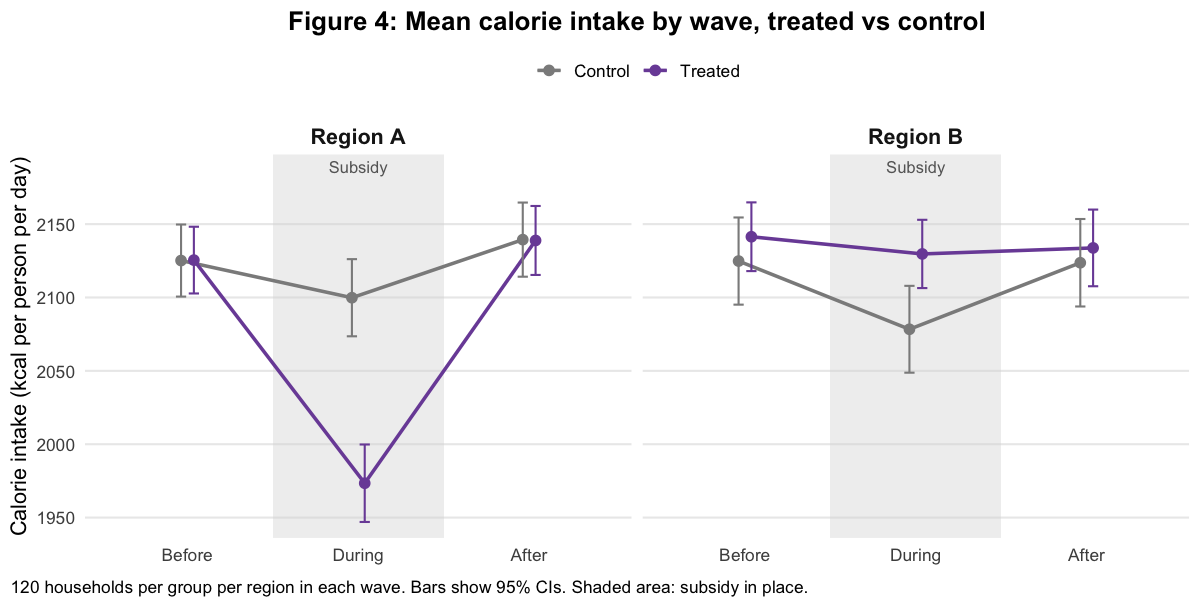

In [12]:
# Plot settings: spacing between groups and figure size
dodge <- position_dodge(0.15)
options(repr.plot.width = 10, repr.plot.height = 5)

# ---- By region ----

# Data: mean and SE of calorie intake by region, wave and group
regression_data |>
  mutate(wave   = factor(wave, levels = c("Before", "During", "After")),
         group  = if_else(treated == 1, "Treated", "Control"),
         region = paste("Region", region)) |>
  group_by(region, wave, group) |>
  summarise(mean_kcal = mean(total_caloric_intake),
            se = sd(total_caloric_intake) / sqrt(n()),
            .groups = "drop") |>

  # Axes: wave on x, mean calories on y, one line per group
  ggplot(aes(wave, mean_kcal, colour = group, group = group)) +

  # Shaded area and label for the During wave (subsidy in place)
  annotate("rect", xmin = 1.5, xmax = 2.5, ymin = -Inf,
           ymax = Inf, fill = "grey85", alpha = 0.4) +
  annotate("text", x = 2, y = Inf, label = "Subsidy",
           vjust = 1.5, colour = "grey40", size = 3.5) +

  # Means with 95% confidence intervals
  geom_line(position = dodge, linewidth = 1) +
  geom_point(position = dodge, size = 2.5) +
  geom_errorbar(aes(ymin = mean_kcal - 1.96 * se, ymax = mean_kcal + 1.96 * se),
                width = 0.12, position = dodge) +

  # One panel per region
  facet_wrap(~ region) +

  # Scales: discrete x axis, extra space on top for the label, group colours
  scale_x_discrete() +
  scale_y_continuous(expand = expansion(mult = c(0.05, 0.15))) +
  scale_colour_manual(values = c(Control = "grey55", Treated = "#7b4fa6")) +

  # Titles and notes
  labs(title = "Figure 4: Mean calorie intake by wave, treated vs control",
       x = NULL, y = "Calorie intake (kcal per person per day)", colour = NULL,
       caption = "120 households per group per region in each wave. Bars show 95% CIs. Shaded area: subsidy in place.") +

  # Visual style
  theme_minimal(base_size = 13) +
  theme(legend.position = "top",
        panel.grid.minor = element_blank(),
        panel.grid.major.x = element_blank(),
        strip.text = element_text(face = "bold", size = 13),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0, vjust = -1),
        plot.caption.position = "plot")


The pilot was a randomised experiment and the regional estimates are precise, so we are confident about the direction of each effect. Clustering standard errors by household allows for the fact that a household's outcomes are related across waves. The main uncertainty is not statistical. With only two regions, we cannot tell which features of a region lead to a fall rather than a rise.

We predicted a small rise in calorie intake. That was right for region B but wrong for region A, where calories fell by more than we thought likely for a subsidy worth about 3 per cent of resources. We explore why the two regions differ and why region A's response is so large below.

##### Question 5

**Economic set-up.** We model a household that chooses between two goods: rice and all other goods. Other goods include fish, oil and vegetables, as well as non-food items. The budget constraint is:

$$p_{rice} \times rice + p_{other} \times other = m$$

where $m$ is cash resources. The subsidy lowers $p_{rice}$ by 25 per cent for treated households, so the budget line pivots outwards along the rice axis.

Households have two motives. They need a minimum number of calories, and rice is the cheapest way to get them. Once they are safely above that minimum, they value the taste and variety that other goods provide; fish, for example, costs about 15 times as much as rice per calorie. This means rice can be an inferior good: as households become better off, they buy less of it and more of other goods.

The subsidy affects rice consumption in two ways (Figure 5):
- the substitution effect (A to C): rice is cheaper relative to other goods, so households buy more rice
- the income effect (C to B): households can still afford their old bundle and have money left over, and if rice is inferior they use that money to buy less rice and more of other goods.

If the income effect is larger than the substitution effect, rice consumption falls when its price falls. Rice is then a 'Giffen good'. This requires rice to be inferior and to take up enough of the budget for the income effect to matter. Jensen and Miller (2011) find this behaviour among poor households in China. Here the income effect is small: the subsidy is worth about 3 per cent of household resources. For rice to behave as a Giffen good, households must therefore be very sensitive to income.

**Connecting the model to our results.** In region A, treated households cut rice and vegetables and sharply increased fish consumption during the subsidy. Rice consumption fell even though rice became cheaper, which is consistent with Giffen behaviour: the income effect outweighed the substitution effect. Because fish supplies far fewer calories per unit of money than rice, calorie intake fell.

In region B, rice consumption did not change significantly, so the two effects roughly offset each other. Households spent most of the money they saved on non-food goods, and a little on oil and fish. Because oil is the most calorie-dense food, calorie intake rose slightly.

The two regions therefore differ in where the freed resources went: towards fish, a costly source of calories, in region A, and towards non-food goods and oil in region B. Our design does not identify the separate income and substitution effects, only their combined result. Nor does it reveal why the regions differ. Before the pilot, the two regions had almost identical resources, rice budget shares and calorie intake (Table 3), so differences in poverty or diet cannot explain the gap. Differences in preferences is one possible explanation.

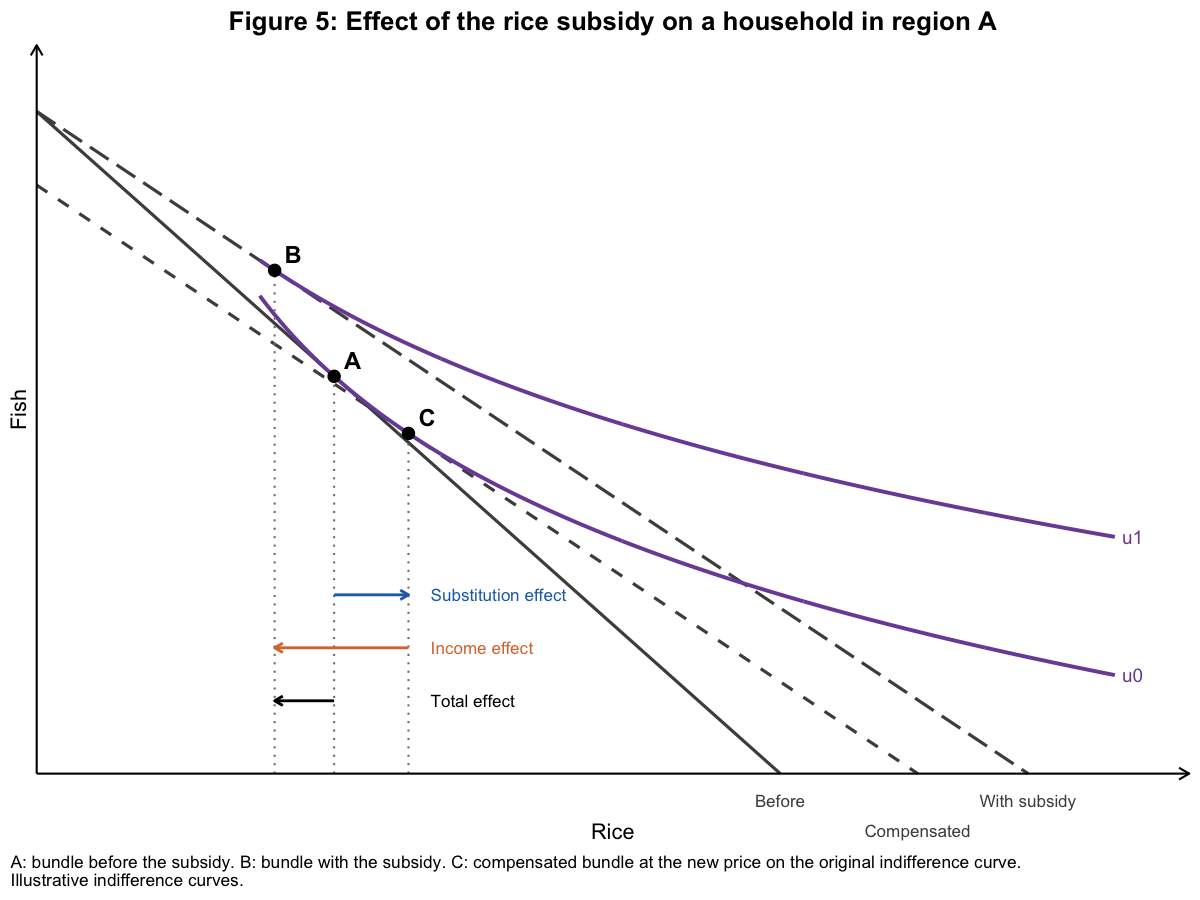

In [13]:
b <- 3
g <- 3
m <- 10
p_fish <- 1
p_old  <- 1
p_new  <- 0.75

ic <- function(x, a, e) a - b * log(x - g + e)

# A: tangency with the original budget (slope -1)
xA <- 4;  yA <- (m - p_old * xA) / p_fish
e0 <- b / p_old - (xA - g);  a0 <- yA + b * log(xA - g + e0)

# B: tangency with the subsidy budget (slope -0.75), with less rice than A
xB <- 3.2;  yB <- (m - p_new * xB) / p_fish
e1 <- b / p_new - (xB - g);  a1 <- yB + b * log(xB - g + e1)

# C: tangency of the original curve with a budget at the new price
xC <- g + b / p_new - e0;  yC <- ic(xC, a0, e0)
m_comp <- p_new * xC + p_fish * yC

# Budget lines: each one goes from its fish intercept to its rice intercept
budgets <- tibble(
  line  = c("before", "subsidy", "compensated"),
  label = c("Before", "With subsidy", "Compensated"),
  y_int = c(m, m, m_comp) / p_fish,
  x_int = c(m / p_old, m / p_new, m_comp / p_new),
  y_lab = c(-0.4, -0.4, -0.85))

# Indifference curves start at the subsistence level
x_grid <- seq(g, 14.5, length.out = 600)

curves <- bind_rows(
  tibble(x = x_grid, y = ic(x_grid, a0, e0), line = "u0"),
  tibble(x = x_grid, y = ic(x_grid, a1, e1), line = "u1"))

points <- tibble(x = c(xA, xC, xB), y = c(yA, yC, yB), label = c("A", "C", "B"))

# Diagram
options(repr.plot.width = 10, repr.plot.height = 7.5)

ggplot() +

  # Rice subsistence level
 #annotate("segment", x = g, xend = g, y = 0, yend = 10.5, linetype = "dashed", colour = "grey60") +
 # annotate("text", x = g - 0.15, y = 10.5, label = "Rice subsistence level",
  #         hjust = 1, colour = "grey40", size = 3.6) +

  # Budget lines from intercept to intercept, labelled below the rice axis
  geom_segment(data = budgets, aes(x = 0, y = y_int, xend = x_int, yend = 0, linetype = line),
               colour = "grey30", linewidth = 0.9) +
  geom_text(data = budgets, aes(x = x_int, y = y_lab, label = label), colour = "grey30", size = 3.6) +

  # Indifference curves, labelled at their right end
  geom_line(data = curves, aes(x, y, group = line), colour = "#7b4fa6", linewidth = 1.1) +
  annotate("text", x = 14.6, y = c(ic(14.5, a0, e0), ic(14.5, a1, e1)), label = c("u0", "u1"),
           colour = "#7b4fa6", hjust = 0, size = 4) +

  # Bundles and guides to the rice axis
  annotate("segment", x = points$x, xend = points$x, y = 0, yend = points$y,
           linetype = "dotted", colour = "grey50") +
  geom_point(data = points, aes(x, y), size = 3) +
  geom_text(data = points, aes(x, y, label = label),
            nudge_x = 0.25, nudge_y = 0.25, fontface = "bold", size = 5) +

  # Substitution, income and total effects on rice, labelled to the right of the arrows
  annotate("segment", x = xA, xend = xC, y = 2.7, yend = 2.7,
           arrow = arrow(length = unit(0.2, "cm")), colour = "#1f6fb4", linewidth = 0.8) +
  annotate("segment", x = xC, xend = xB, y = 1.9, yend = 1.9,
           arrow = arrow(length = unit(0.2, "cm")), colour = "#d9773b", linewidth = 0.8) +
  annotate("segment", x = xA, xend = xB, y = 1.1, yend = 1.1,
           arrow = arrow(length = unit(0.2, "cm")), colour = "black", linewidth = 0.8) +
  annotate("text", x = xC + 0.3, y = c(2.7, 1.9, 1.1),
           label = c("Substitution effect", "Income effect", "Total effect"),
           colour = c("#1f6fb4", "#d9773b", "black"), hjust = 0, size = 3.6) +

  # Scales: axes start at the origin; clip = "off" lets labels sit below the axis
  scale_linetype_manual(values = c(before = "solid", subsidy = "longdash", compensated = "dashed"),
                        guide = "none") +
  coord_cartesian(xlim = c(0, 15.5), ylim = c(0, 11), expand = FALSE, clip = "off") +

  # Titles and notes
  labs(title = "Figure 5: Effect of the rice subsidy on a household in region A",
       x = "Rice", y = "Fish",
       caption = "A: bundle before the subsidy. B: bundle with the subsidy. C: compensated bundle at the new price on the original indifference curve.\nIllustrative indifference curves.") +

  # Textbook style: axes only, no numbers or grid
  theme_minimal(base_size = 13) +
  theme(panel.grid = element_blank(),
        axis.text = element_blank(),
        axis.line = element_line(colour = "black", arrow = arrow(length = unit(0.25, "cm"))),
        axis.title.x = element_text(margin = margin(t = 30)),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0),
        plot.caption.position = "plot")

##### Question 6

**Households with subsidy in Region A mainly consumed more fish, while Region B households consumed more non-food goods**

It is important to check which changes in food consumption explain the variations in calorie intake (Tables 7 and 8 and the food-consumption figures). Compared with control households, treated households in region A show the following changes during the subsidy:

- Consumption of rice and vegetables falls by 56.5 and 9.2 grams per person per day, respectively.
- Consumption of oil and fish rises by 0.6 and 61.6 grams per person per day, respectively.

In region B we find:

- No significant change in the grams consumed of rice and vegetables.
- Consumption of oil and fish rises by 2.1 and 3.2 grams per person per day, respectively.

All of these changes disappear in the After wave.

In [14]:
food_data <- raw_data |>
  mutate(wave_during = as.integer(wave == "During"),
         wave_after  = as.integer(wave == "After"))

regression_per_food <- function(f, r) {
  feols(grams_consumed ~ treated:wave_during + treated:wave_after | household_id + wave,
        data = filter(food_data, food == f, region == r), cluster = ~household_id)
}

tbl6 <- modelsummary(list("Rice, Region A" = regression_per_food("rice", "A"),
                          "Rice, Region B" = regression_per_food("rice", "B"),
                          "Fish, Region A" = regression_per_food("fish", "A"),
                          "Fish, Region B" = regression_per_food("fish", "B")),
                     coef_map = c("treated:wave_during" = "Treated × During",
                                  "treated:wave_after"  = "Treated × After"),
                     stars   = c("*" = 0.10, "**" = 0.05, "***" = 0.01),
                     gof_map = c("nobs", "r.squared"),
                     output  = "gt") |>
  tab_header(title = "Table 7: Effect of the rice subsidy on rice and fish consumption, by region") |>
  tab_source_note("Dependent variable: grams consumed per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.")

IRdisplay::display_html(as_raw_html(tbl6))

"* p < 0.1, ** p < 0.05, *** p < 0.01"
Dependent variable: grams consumed per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.


In [15]:
tbl7 <- modelsummary(list("Vegetables, Region A" = regression_per_food("vegetables", "A"),
                          "Vegetables, Region B" = regression_per_food("vegetables", "B"),
                          "Oil, Region A" = regression_per_food("oil", "A"),
                          "Oil, Region B" = regression_per_food("oil", "B")),
                     coef_map = c("treated:wave_during" = "Treated × During",
                                  "treated:wave_after"  = "Treated × After"),
                     stars   = c("*" = 0.10, "**" = 0.05, "***" = 0.01),
                     gof_map = c("nobs", "r.squared"),
                     output  = "gt") |>
  tab_header(title = "Table 8: Effect of the rice subsidy on vegetables and oil consumption, by region") |>
  tab_source_note("Dependent variable: grams consumed per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.")

IRdisplay::display_html(as_raw_html(tbl7))

"* p < 0.1, ** p < 0.05, *** p < 0.01"
Dependent variable: grams consumed per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.


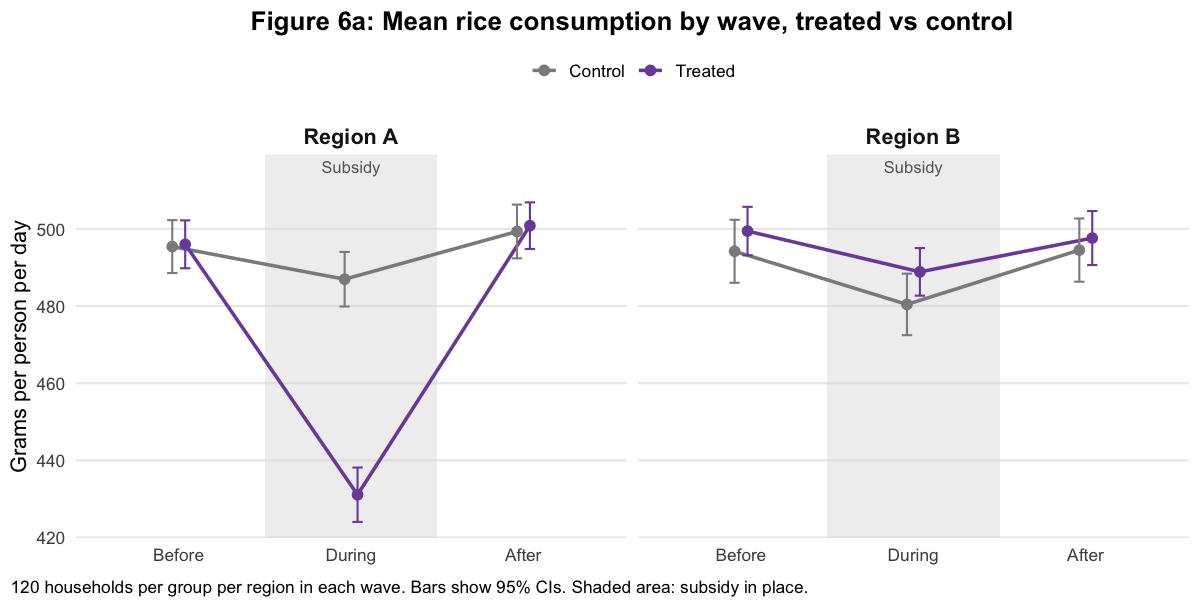

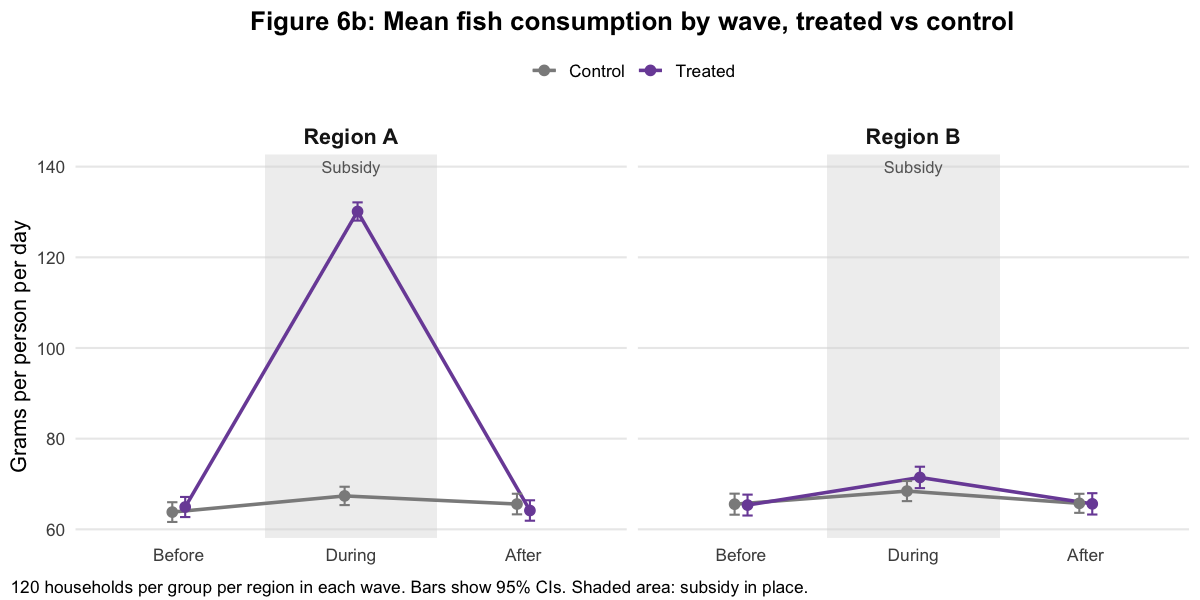

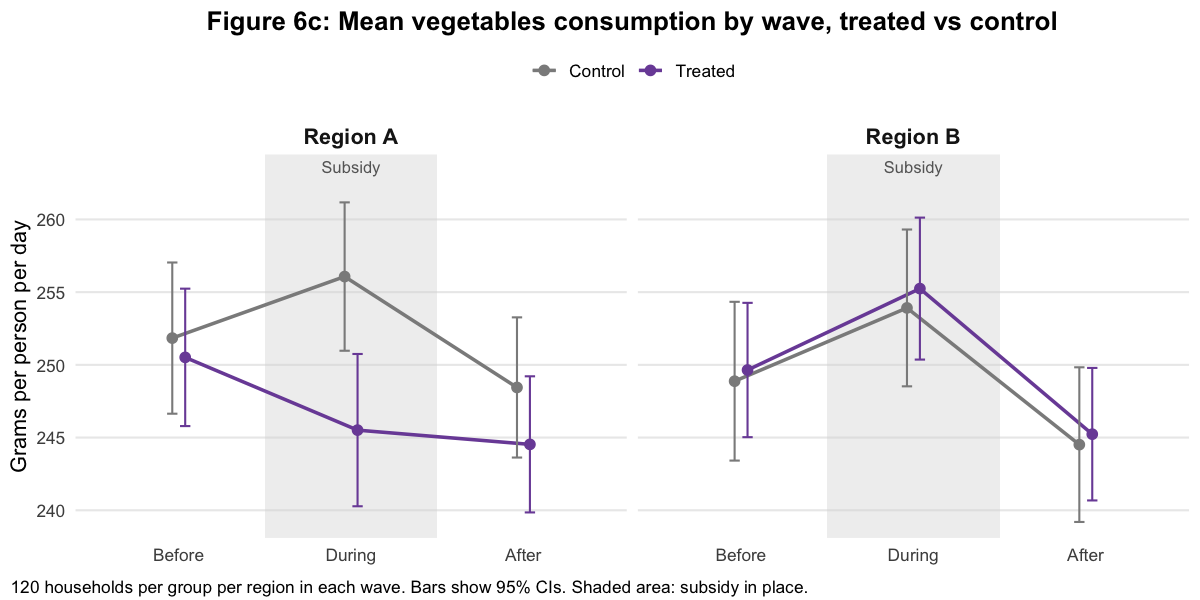

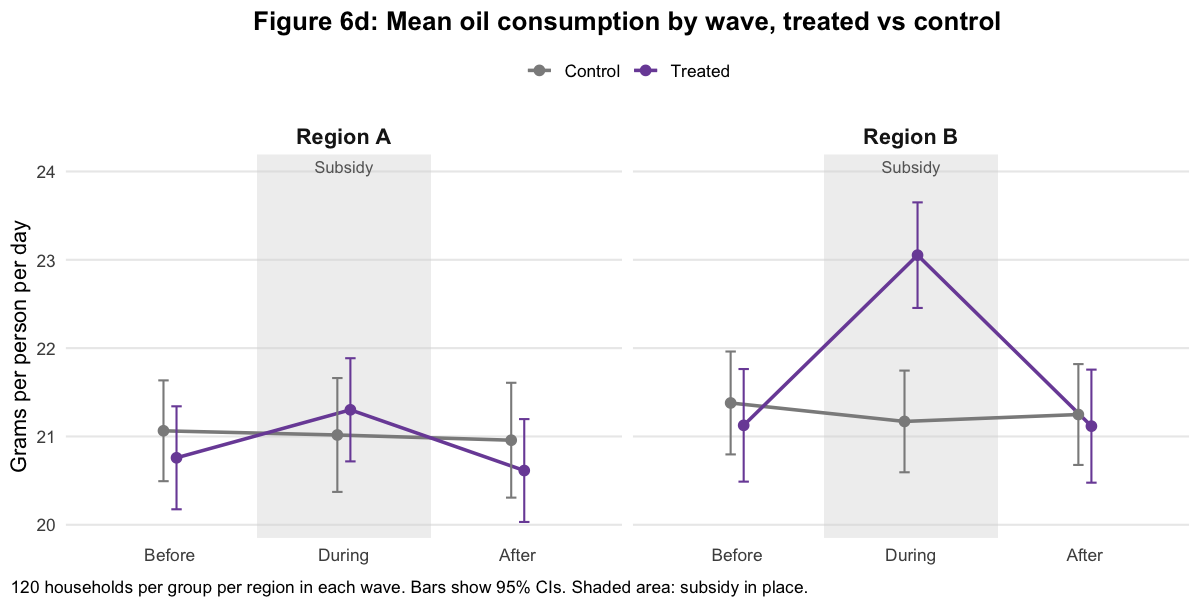

In [16]:
# Plot settings: spacing between groups and figure size
dodge <- position_dodge(0.15)
options(repr.plot.width = 10, repr.plot.height = 5)

# Data: mean and SE of grams consumed by food, region, wave and group
food_means <- raw_data |>
  mutate(wave   = factor(wave, levels = c("Before", "During", "After")),
         group  = if_else(treated == 1, "Treated", "Control"),
         region = paste("Region", region)) |>
  group_by(food, region, wave, group) |>
  summarise(mean = mean(grams_consumed),
            se = sd(grams_consumed) / sqrt(n()),
            .groups = "drop")

foods <- c("rice", "fish", "vegetables", "oil")

# One figure per food
for (f in foods) {
  p <- ggplot(filter(food_means, food == f), aes(wave, mean, colour = group, group = group)) +

    # Shaded area and label for the During wave (subsidy in place)
    annotate("rect", xmin = 1.5, xmax = 2.5, ymin = -Inf,
             ymax = Inf, fill = "grey85", alpha = 0.4) +
    annotate("text", x = 2, y = Inf, label = "Subsidy",
             vjust = 1.5, colour = "grey40", size = 3.5) +

    # Means with 95% confidence intervals
    geom_line(position = dodge, linewidth = 1) +
    geom_point(position = dodge, size = 2.5) +
    geom_errorbar(aes(ymin = mean - 1.96 * se, ymax = mean + 1.96 * se),
                  width = 0.12, position = dodge) +

    # One panel per region
    facet_wrap(~ region) +

    # Scales: discrete x axis, extra space on top for the label, group colours
    scale_x_discrete() +
    scale_y_continuous(expand = expansion(mult = c(0.05, 0.15))) +
    scale_colour_manual(values = c(Control = "grey55", Treated = "#7b4fa6")) +

    # Titles and notes
    labs(title = paste0("Figure 6", letters[which(foods == f)], ": Mean ", f, " consumption by wave, treated vs control"),
         x = NULL, y = "Grams per person per day", colour = NULL,
         caption = "120 households per group per region in each wave. Bars show 95% CIs. Shaded area: subsidy in place.") +

    # Visual style
    theme_minimal(base_size = 13) +
    theme(legend.position = "top",
          panel.grid.minor = element_blank(),
          panel.grid.major.x = element_blank(),
          strip.text = element_text(face = "bold", size = 13),
          plot.title = element_text(face = "bold", hjust = 0.5),
          plot.caption = element_text(hjust = 0, vjust = -1),
          plot.caption.position = "plot")

  print(p)
}


It is important to take into account what Figure 7 shows. The bars for each food add up to the total effect of the subsidy on calorie intake in each region. For region A, we can clearly see that there are two dominating effects: the calories from fish increased, while the calories from rice decreased by much more. This is compatible with our estimates, since households replaced rice with fish, which provides fewer calories per gram.

However, for region B the effect on calories from rice is positive but not statistically significant, and the increase is mainly driven by oil. This explains why the households in this region experienced an increase in calorie intake. This does not imply that region B is eating healthier, since we do not have information about the evolution in the consumption of micronutrients or proteins. For the same reason, we cannot say that region A is eating worse, as fish may provide more protein than rice.

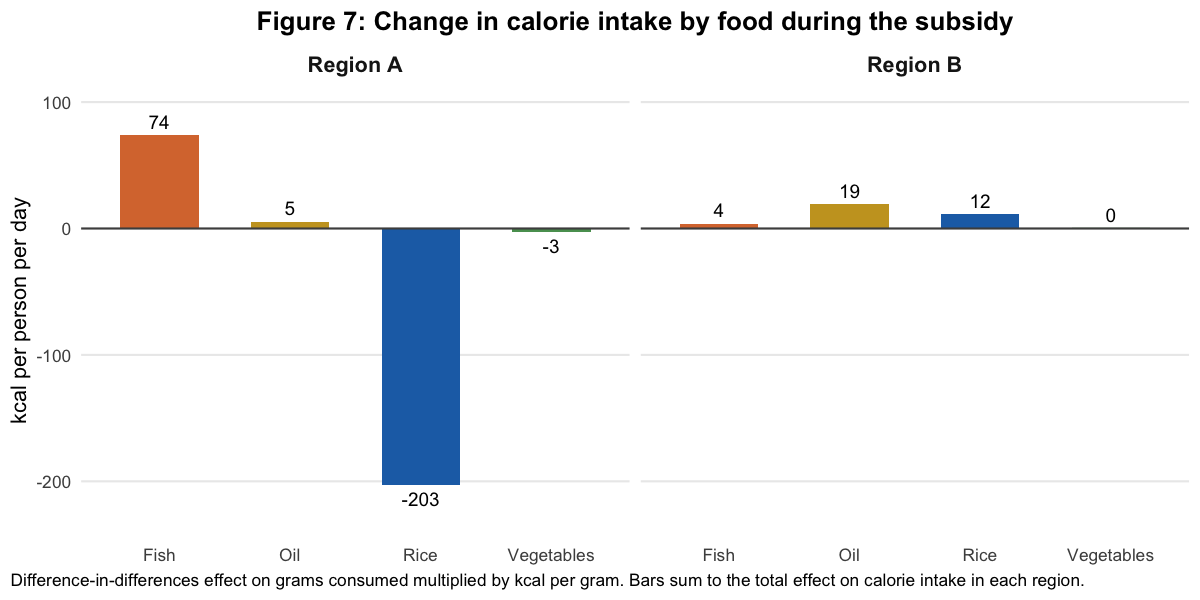

In [17]:
kcal_per_g <- c(rice = 3.6, fish = 1.2, vegetables = 0.3, oil = 9.0)

# Effect of the subsidy on calories from each food, by region
decomp <- expand_grid(food = names(kcal_per_g), region = c("A", "B")) |>
  rowwise() |>
  mutate(grams = coef(regression_per_food(food, region))["treated:wave_during"]) |>
  ungroup() |>
  mutate(kcal   = grams * kcal_per_g[food],
         food   = str_to_title(food),
         region = paste("Region", region))

# Diverging bar chart
options(repr.plot.width = 10, repr.plot.height = 5)

ggplot(decomp, aes(food, kcal, fill = food)) +
  geom_col(width = 0.6) +
  geom_hline(yintercept = 0, colour = "grey30") +
  geom_text(aes(label = round(kcal), vjust = if_else(kcal >= 0, -0.5, 1.5)), size = 4) +
  facet_wrap(~ region) +
  scale_fill_manual(values = c(Rice = "#1f6fb4", Oil = "#c9a227",
                               Fish = "#d9773b", Vegetables = "#5a9e5f"),
                    guide = "none") +
  scale_y_continuous(expand = expansion(mult = 0.15)) +
  labs(title = "Figure 7: Change in calorie intake by food during the subsidy",
       x = NULL, y = "kcal per person per day",
       caption = "Difference-in-differences effect on grams consumed multiplied by kcal per gram. Bars sum to the total effect on calorie intake in each region.") +
  theme_minimal(base_size = 13) +
  theme(panel.grid.minor = element_blank(),
        panel.grid.major.x = element_blank(),
        strip.text = element_text(face = "bold", size = 13),
        plot.title = element_text(face = "bold", hjust = 0.5),
        plot.caption = element_text(hjust = 0),
        plot.caption.position = "plot")

It is also important to consider how the subsidy changes the way households allocate their resources between food and other goods. Table 9 shows that this differs between regions. Since cash resources do not change, any increase in food spending implies an equal decrease in other spending. On the one hand, in region A the subsidy led households to spend more on food than control households, even though rice became cheaper, because they spent much more on fish. They spent on fish all the money saved on rice and also reduced their spending on other goods.

On the other hand, in region B households spent less on food than control households. Most of the money freed by the subsidy went to other goods, and only a small part went to oil and fish.

In [18]:
spend_data <- filter(food_data, food == "rice")

spend_model <- function(v, r) {
  feols(as.formula(paste(v, "~ treated:wave_during + treated:wave_after | household_id + wave")),
        data = filter(spend_data, region == r), cluster = ~household_id)
}

tbl8 <- modelsummary(list("Food spending, A"  = spend_model("food_spending", "A"),
                          "Food spending, B"  = spend_model("food_spending", "B"),
                          "Other spending, A" = spend_model("other_spending", "A"),
                          "Other spending, B" = spend_model("other_spending", "B")),
                     coef_map = c("treated:wave_during" = "Treated × During",
                                  "treated:wave_after"  = "Treated × After"),
                     stars   = c("*" = 0.10, "**" = 0.05, "***" = 0.01),
                     gof_map = c("nobs"),
                     output  = "gt") |>
  tab_header(title = "Table 9: Effect of the rice subsidy on spending, by region") |>
  tab_source_note("Dependent variable: currency units per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.")

IRdisplay::display_html(as_raw_html(tbl8))

"* p < 0.1, ** p < 0.05, *** p < 0.01"
Dependent variable: currency units per person per day. Household and wave fixed effects. Standard errors clustered by household in parentheses.


An alternative explanation for region B is that households already cover their food needs, so their demand for food does not respond to the lower price of rice. In that case, they keep buying the same amount of rice and spend the money saved on other goods instead of on more food. The evidence for region B is consistent with this explanation: rice consumption does not change significantly (Table 7) and food spending falls (Table 9).

This explanation cannot account for region A, where food spending rises. There, the money freed by the subsidy did not go to other goods but to fish, which is consistent with the proposed Giffen-type mechanism, although it does not establish the separate income and substitution effects. However, the data only describe how households reallocated their spending; they cannot tell us why preferences differ between the two regions.

##### Question 7: Brief the policymaker

**We recommend that the subsidy be revised**

The pilot offered a randomly selected half of 480 households a 25 per cent discount on rice. During the subsidy, their calorie intake fell by 46 kcal per person per day relative to other households. The effect differed by region: intake fell by 127 kcal (about 6 per cent) in region A and rose by 35 kcal (about 2 per cent) in region B. Neither region showed a statistically significant lasting effect after the subsidy ended. Expanding it as designed would therefore not meet the government's objective.

Cheaper rice freed up money, which many households chose not to spend on calories. In region A, households replaced rice with fish, which costs around 15 times as much per calorie; in region B, they kept buying the same rice and spent most of the savings on non-food goods. Lower calorie intake does not mean households were worse off. While the pilot fell short on its nutrition objective, each treated household could still afford its original purchases and chose a different mix, so by its own judgement it was better off under standard consumer-choice assumptions, its welfare could have improved. The subsidy likely improved household welfare.

We recommend a trial of support for households with the lowest calorie intake, such as food in kind, that measures protein and micronutrients as well as calories. Because the pilot covered two regions, one subsidy rate and a short period, and cannot explain why the regions differed, its results may not hold more widely.